In [54]:
# from discopy.abc import MonoidalCategory
# from discopy import *
# from discopy.abc import Category
import discopy.frobenius as frob
from discopy.drawing import Equation
import json

In [52]:
# This block from https://stackoverflow.com/a/2158532

from collections.abc import Iterable

def flatten(xs):
    for x in xs:
        if isinstance(x, Iterable) and not isinstance(x, (str, bytes)):
            yield from flatten(x)
        else:
            yield x

In [154]:
class JSON2Diag:
    def __init__(self, parsers : dict[str, Callable[[json, Callable[[json],Category]], Category]] = {}) :
        self.parsers = parsers

    def __call__(self, d : json) -> any :
        ty = d["type"]
        if ty not in self.parsers:
            raise ValueError(f"key {ty} not found (available parsers are {list((self.parsers).keys())}")
        par = self.parsers[ty]
        return par(d, self)

    def copy(self):
        return self.__class__(self.parsers.copy())

    def __or__(self, other) :
        # out = JSON2Diag(self.parsers | other.parsers)
        # print (f"ORED : {list(self.parsers.keys())} + {list(other.parsers.keys())} = {list(out.parsers.keys())}")
        return JSON2Diag(self.parsers | other.parsers)
        

class ComposeStack2Diag(JSON2Diag):
    def __init__(self, par : JSON2Diag):
        self.parsers = par.parsers
        self.parsers["compose"] = lambda d, par : par(d["left"]) >> par(d["right"])
        self.parsers["stack"] = lambda d, par : par(d["bottom"]) @ par(d["top"])
        # self.parsers["compose"] = lambda (d, par:
        #     par(d["left"] >> d["right"])

class Struct2Diag(JSON2Diag):
    def __init__(self, parse_struct : JSON2Diag):
        self.parsers = {
            "struct" : lambda d, _: parse_struct(d["data"])
        }

class Gen2Diag(JSON2Diag):
    def __init__(self, parse_gen : Callable[[json, json, json], Category]):
        self.parsers = {
            "gen" : lambda d, _: parse_gen(d["insize"], d["outsize"], d["data"])
        }

def join_diagram_parsers(struct_parser : JSON2Diag, gen_parser : JSON2Diag) -> JSON2Diag :
    # gen_struct_parser = JSON2Diag({
    #     "struct" : lambda d, _ : struct_parser(d["data"]),
    #     "gen" : lambda d, _ : gen_parser(d["data"])})
    return ComposeStack2Diag(struct_parser | gen_parser)

def make_struct_parser(mk_size : Callable[[json], "size"],
    mk_id : Callable[["size"], Category],
    mk_swap : Callable[["size", "size"], Category],
    mk_cup : Callable[["size"], Category],
    mk_cap : Callable[["size"], Category],
    mk_delta : Callable[["size", "size", "size"], Category] ) -> JSON2Diag :
    return JSON2Diag({
            "id" : lambda d, _ : mk_id(mk_size(d["size"])) ,
            "associator" : lambda d, _ : mk_id(mk_size(d["size"])) ,
            "swap" : lambda d, _ : mk_swap(mk_size(d["top"]), mk_size(d["bottom"])) ,
            "cup" : lambda d, _ : mk_cup(mk_size(d["size"])) ,
            "cap" : lambda d, _ : mk_cap(mk_size(d["size"])) ,
            "delta" : lambda d, _ : mk_delta(mk_size(d["insize"]), mk_size(d["outsize"]), mk_size(d["spidertype"]))
        })

def make_diagram_parser(gen_parser_of_mk_size, mk_ty, mk_id, mk_swap, mk_cup, mk_cap, mk_delta) -> JSON2Diag :
    def parse_diagram(d, _) :
        if "types" not in d or (types := [mk_ty(t) for t in d["types"]]) == []:
            types = [mk_ty("1")]
        def of_tys(tyidxs : list[int]):
            return mk_ty().tensor(*(types[idx] for idx in tyidxs))
        def mk_size(idxs) : #possibly arbitrarity nested lists of ints
            if not isinstance(idxs, list):
                idxs = [idxs]
            return of_tys(flatten(idxs))
        struct_parser = make_struct_parser(mk_size, mk_id, mk_swap, mk_cup, mk_cap, mk_delta)
        diagram_parser = join_diagram_parsers(Struct2Diag(struct_parser), gen_parser_of_mk_size(mk_size))
        return diagram_parser(d["data"])
        
    return JSON2Diag({
        "diagram" : parse_diagram
    })

In [155]:
def generic_gen_parser_of_size(mk_box, mk_size) -> JSON2Diag :
    return Gen2Diag(lambda n, m, d : mk_box(str(d), mk_size(n), mk_size(m)))

In [156]:
def frob_diagram_parser(gen_parser_of_mk_size) -> JSON2Diag :
    return make_diagram_parser(gen_parser_of_mk_size, frob.Ty, frob.Id, frob.Swap,
                                lambda n : frob.Cup(n, n),
                                lambda n : frob.Cap(n, n),
                                lambda n, m, ty : frob.Delta(len(n), len(m), ty))

generic_frob_diagram_parser = frob_diagram_parser(
    lambda mk_size : generic_gen_parser_of_size(frob.Box, mk_size))

In [157]:
example_diagram_json_1 = """
{"data" : {"left" : {"data" : "1%positive", "insize" : [0], 
"outsize" : [0, 0], "type" : "gen"},
"right" : {"left" : {"data" : {"bottom" : [0], "top" : [0], 
"type" : "swap"}, "insize" : [0, 0], "outsize" : [0, 0], 
"type" : "struct"}, "right" : {"bottom" : {"data" : 
"5%positive", "insize" : [0], "outsize" : [], "type" : 
"gen"}, "top" : {"data" : "10%positive", "insize" : [0], 
"outsize" : [0, 0], "type" : "gen"}, "type" : "stack"}, 
"type" : "compose"}, "type" : "compose"}, "type" : 
"diagram", "types" : ["1"]}"""

example_diagram_json_1_parsed = json.loads(example_diagram_json_1)

In [158]:
example_diagram_json_2 = """{"data" : {"left" : {"data" : "1", "insize" : [0], 
"outsize" : [0, 0], "type" : "gen"},
"right" : {"left" : {"data" : {"bottom" : [0], "top" : [0], 
"type" : "swap"}, "insize" : [0, 0], "outsize" : [0, 0], 
"type" : "struct"}, "right" : {"bottom" : {"data" : 
"5", "insize" : [0], "outsize" : [], "type" : "gen"}, 
"top" : {"data" : "10", "insize" : [0], "outsize" : [0, 0], 
"type" : "gen"}, "type" : "stack"}, "type" : "compose"}, 
"type" : "compose"}, "type" : "diagram", "types" : [
"1"]}"""

example_diagram_json_2_parsed = json.loads(example_diagram_json_2)

In [177]:
example = """{"data" : {"left" : {"data" : "1", "insize" : [0], 
"outsize" : [0, 0], "type" : "gen"},
"right" : {"left" : {"data" : {"insize" : [0,0], "outsize" : [0,0], "spidertype" : 0,
"type" : "delta"}, "insize" : [0, 0], "outsize" : [0, 0], 
"type" : "struct"}, "right" : {"bottom" : {"data" : 
"5", "insize" : [0], "outsize" : [0], "type" : "gen"},
"top" : {"data" : "10", "insize" : [0], "outsize" : [0, 0], 
"type" : "gen"}, "type" : "stack"}, "type" : "compose"}, 
"type" : "compose"}, "type" : "diagram", "types" : [
"1"]}"""

example_parsed = json.loads(example)

In [178]:
# HERE IS WHAT YOU DO TO RENDER:

# If s is a string containing the json, run either one of:
# generic_frob_diagram_parser(json.loads(s)).draw()
# or
# generic_frob_diagram_parser(json.loads(s)).simplify().foliation().draw()


generic_frob_diagram_parser(example_parsed).draw()

AttributeError: module 'discopy.frobenius' has no attribute 'Delta'

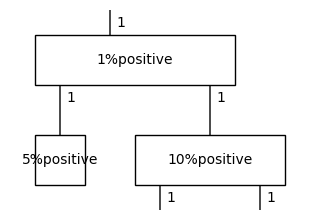

In [146]:
generic_frob_diagram_parser(example_diagram_json_1_parsed).simplify().foliation().draw()

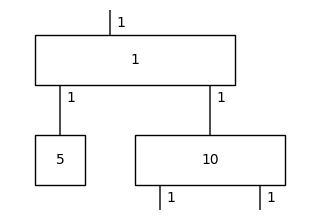

In [147]:
generic_frob_diagram_parser(example_diagram_json_2_parsed).simplify().foliation().draw()

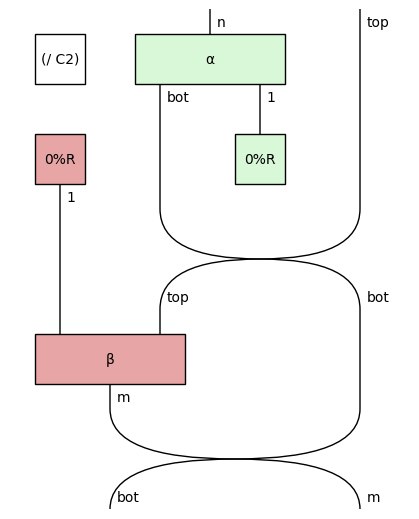

In [4]:
tys = [Ty(var) for var in ["n", "top", "bot", "m"]]
tyone = Ty("1")
tyempt = Ty()
n, top, bot, m = tys

def of_tys(tyidxs : list[int]) -> Ty :
    return Ty().tensor(*(tys[idx] if idx >= 0 else tyone for idx in tyidxs))

def gadget(phase: str) -> Box :
    return Box(phase, tyempt, tyempt, draw_as_spider=False, color="white", shape="circle")

def spider(phase: str, is_X : bool, domtys, codomtys, *args, **kwargs) -> Box :
    return Box (phase, of_tys(domtys), of_tys(codomtys), 
                *args, draw_as_spider=False, color="red" if is_X else "green", **kwargs)

def id(dom) -> Box :
    return Id(of_tys(dom))

def swap(l, r) -> Box :
    return Swap(of_tys(l), of_tys(r))

diag = ((((id([0, 1])) >> ((spider('α', False, [0], [2, -1])) @ (id([1])))) >> \
  ((((id([2])) @ ((swap([-1], [1])) @ (id([])))) >> \
	((swap([2], [1])) @ (id([-1])))) >> ((id([1])) @ (id([2, -1]))))) >> \
 ((id([1, 2])) @ ((gadget('(/ C2)')) @ ((spider('0%R', False, [-1], [])) >> \
                                        (spider('0%R', True, 
                                         [], [-1])))))) >> \
((((((id([1])) @ ((swap([2], [-1])) @ (id([])))) >> \
    ((swap([1], [-1])) @ (id([2])))) >> ((id([-1])) @ (id([1, 2])))) >> \
  ((spider('β', True, [-1, 1], [3])) @ (id([2])))) >> \
 (swap([3], [2])))

diag.simplify().foliation().draw()

# diag = ((gadget("/ 2")) @ 
#         (spider("$\\beta$", True, ([2]), ([3]))) @
#         (spider("$\\alpha$", False, ([0]), ([1]))))
# diag.draw()
# diag.foliation().draw()
# diag.dom.name, diag.cod.name
# Equation(diag, diag.normal_form()).draw()
# diag = (#(Box("/ 2", tyempt, tyempt)) @ 
#         (n @ spider("$0 + \\beta$", True, of_tys([2]), of_tys([3]))) >>
#         (spider("$0 + \\alpha$", False, of_tys([0]), of_tys([1])) @ m))
# diag.draw()
# diag.dom.name, diag.cod.name
# diag.normal_form().draw()
# diag.simplify()
# diag.to_hypergraph()

In [71]:
from discopy.symmetric import *
x, y = Ty('x'), Ty('y')
f = spider('f', True, x, y)
f.simplify()

symmetric.Diagram(inside=(monoidal.Layer(monoidal.Ty(), symmetric.Box('f', monoidal.Ty(cat.Ob('x')), monoidal.Ty(cat.Ob('y'))), monoidal.Ty()),), dom=monoidal.Ty(cat.Ob('x')), cod=monoidal.Ty(cat.Ob('y')))

In [74]:
x

monoidal.Ty(cat.Ob('x'))

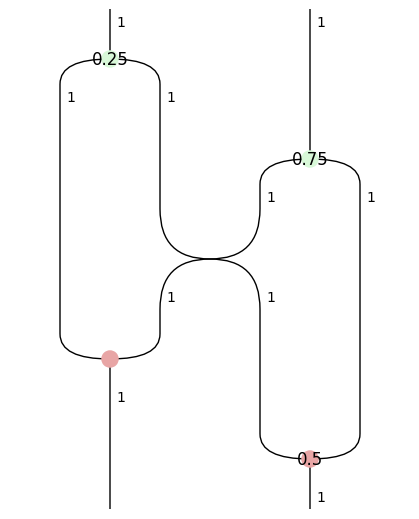

In [6]:
from discopy.quantum.zx import *
from pyzx import draw

bialgebra = Z(1, 2, .25) @ Z(1, 2, .75) >> Id(1) @ SWAP @ Id(1) >> X(2, 1) @ X(2, 1, .5)
bialgebra.draw(aspect='equal')
draw(bialgebra.to_pyzx())